In [1]:
from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)

PROCESSED = Path("processed")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

DATA_PATH = (
    PROCESSED /
    "burninwatch_modeling_dataset_final.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset:", df.shape)
display(df.head())


Dataset: (687, 40)


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,supplyVoltage_mean,supplyVoltage_std,node2Voltage_mean,node2Voltage_std,node2Voltage_iqr,node2Voltage_slope,collectorEmitterCurrent_mean,collectorEmitterCurrent_std,collectorEmitterCurrent_q05,collectorEmitterCurrent_q95,collectorEmitterCurrent_iqr,collectorEmitterCurrent_slope,packageTemperature_mean,packageTemperature_std,packageTemperature_q05,packageTemperature_q95,packageTemperature_iqr,packageTemperature_slope,supply_node1_mean_diff,node1_node2_mean_diff,estimated_power_proxy,node2Voltage_delta_from_baseline,node2Voltage_pct_change_from_baseline,collectorEmitterCurrent_delta_from_baseline,collectorEmitterCurrent_pct_change_from_baseline,packageTemperature_delta_from_baseline,packageTemperature_pct_change_from_baseline,current_residual,current_residual_abs,package_temperature_residual,current_per_node2V,node_voltage_drop
0,0,Device_2,Device2 1.mat,main,0,100,0.000,22.671,2.454372,0.006901,1.952854,0.103817,0.139707,0.005401,0.118606,0.056871,0.080834,0.174992,0.072177,0.000347,44.674700,10.876925,30.402502,62.593386,19.625527,1.644183,0.003014,0.498504,0.231621,-0.073491,-0.036268,0.000000,0.000000,-33.393921,-0.427751,0.001394,0.001394,-51.722321,0.060735,0.498504
1,1,Device_2,Device2 1.mat,main,1,100,22.911,45.542,2.454399,0.006417,2.026345,0.088584,0.156998,0.001211,0.119897,0.048703,0.083021,0.164384,0.063428,-0.000851,78.068621,6.957067,66.747572,88.169319,11.951787,1.054713,0.002392,0.425662,0.242952,0.000000,0.000000,0.001290,0.010880,0.000000,0.000000,0.006630,0.006630,-18.328890,0.059169,0.425662
2,2,Device_2,Device2 1.mat,main,2,100,45.776,68.042,2.456576,0.005668,2.117639,0.192635,0.195728,0.016992,0.107692,0.039220,0.085099,0.157494,0.056867,-0.001148,96.348991,3.567825,90.350834,100.860965,6.200524,0.542141,0.002275,0.336661,0.228053,0.091294,0.045053,-0.010914,-0.092019,18.280369,0.234158,-0.000786,0.000786,-0.086894,0.050855,0.336661
3,3,Device_2,Device2 1.mat,main,3,100,68.282,90.812,2.457120,0.005396,2.097679,0.151077,0.127604,-0.009018,0.110033,0.038414,0.085208,0.159682,0.056867,0.001033,97.329904,1.702277,95.143693,100.038545,3.043599,0.046638,0.002626,0.356815,0.230813,0.071334,0.035203,-0.008574,-0.072287,19.261282,0.246722,0.000454,0.000454,0.884389,0.052454,0.356815
4,4,Device_2,Device2 1.mat,main,4,100,91.050,113.501,2.457609,0.005506,2.171392,0.208924,0.456469,-0.023517,0.097325,0.032439,0.083021,0.157385,0.006562,0.000371,97.966307,1.998920,95.579187,101.089235,3.909730,-0.214554,0.001595,0.284622,0.211331,0.145046,0.071580,-0.021281,-0.179428,19.897686,0.254874,-0.008321,0.008321,1.512138,0.044822,0.284622


In [2]:
META = [
    "sample_id",
    "device_id",
    "file_name",
    "file_role",
    "window_index",
    "window_size",
    "window_start_seconds",
    "window_end_seconds",
]

ALL_FEATURES = [
    c for c in df.columns
    if c not in META
]

STRESS_AWARE_FEATURES = [
    "node2Voltage_std",
    "node2Voltage_iqr",
    "node2Voltage_slope",

    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_q05",
    "collectorEmitterCurrent_q95",
    "collectorEmitterCurrent_iqr",
    "collectorEmitterCurrent_slope",

    "packageTemperature_std",
    "packageTemperature_iqr",

    "collectorEmitterCurrent_delta_from_baseline",
    "collectorEmitterCurrent_pct_change_from_baseline",

    "current_residual",
    "current_residual_abs",

    "current_per_node2V",
    "node_voltage_drop",
]

COMPACT_FEATURES = [
    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_iqr",
    "collectorEmitterCurrent_slope",

    "collectorEmitterCurrent_delta_from_baseline",
    "collectorEmitterCurrent_pct_change_from_baseline",

    "current_residual",
    "current_residual_abs",

    "current_per_node2V",
    "node_voltage_drop",

    "node2Voltage_std",
    "node2Voltage_iqr",

    "packageTemperature_std",
    "packageTemperature_iqr",
]

FEATURE_SETS = {
    "all_32": ALL_FEATURES,
    "stress_aware": STRESS_AWARE_FEATURES,
    "compact_response": COMPACT_FEATURES,
}

for name, features in FEATURE_SETS.items():
    print(name, len(features))

all_32 32
stress_aware 17
compact_response 14


In [3]:
# ============================================================
# TEMPORAL SPLIT
# ============================================================

work = df.copy()

work = work.sort_values(
    [
        "device_id",
        "file_name",
        "window_index"
    ]
).reset_index(drop=True)

work["split"] = "excluded"

for (device_id, file_name), group in work.groupby(
    ["device_id", "file_name"],
    sort=False
):

    group = group.sort_values(
        "window_index"
    )

    indices = group.index.to_numpy()

    role = group["file_role"].iloc[0]
    n = len(group)

    if role == "check":

        work.loc[
            indices,
            "split"
        ] = "check_holdout"

        continue

    if n < 10:

        work.loc[
            indices,
            "split"
        ] = "short_file_holdout"

        continue

    n_train = max(
        3,
        int(np.floor(n * 0.20))
    )

    n_val = max(
        1,
        int(np.floor(n * 0.20))
    )

    work.loc[
        indices[:n_train],
        "split"
    ] = "baseline_train"

    work.loc[
        indices[n_train:n_train + n_val],
        "split"
    ] = "validation"

    work.loc[
        indices[n_train + n_val:],
        "split"
    ] = "evaluation"


print(
    work["split"]
    .value_counts()
)

split
evaluation        415
baseline_train    134
validation        134
check_holdout       4
Name: count, dtype: int64


In [4]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("PyTorch device:", DEVICE)

PyTorch device: cpu


In [5]:
# ============================================================
# AUTOENCODER
# ============================================================

class BurnInAutoencoder(nn.Module):

    def __init__(
        self,
        input_dim,
        bottleneck_dim=8
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),

            nn.Linear(16, bottleneck_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 16),
            nn.ReLU(),

            nn.Linear(16, input_dim),
        )

    def forward(self, x):

        encoded = self.encoder(x)

        reconstructed = self.decoder(
            encoded
        )

        return reconstructed

In [6]:
def train_autoencoder(
    X_train,
    input_dim,
    epochs=300,
    batch_size=16,
    learning_rate=1e-3,
):

    X_train_tensor = torch.tensor(
        X_train,
        dtype=torch.float32
    )

    dataset = TensorDataset(
        X_train_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=min(batch_size, len(dataset)),
        shuffle=True,
    )

    model = BurnInAutoencoder(
        input_dim=input_dim,
        bottleneck_dim=8
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4,
    )

    criterion = nn.MSELoss()

    losses = []

    model.train()

    for epoch in range(epochs):

        epoch_loss = 0.0

        for (batch,) in loader:

            batch = batch.to(DEVICE)

            optimizer.zero_grad()

            reconstructed = model(
                batch
            )

            loss = criterion(
                reconstructed,
                batch
            )

            loss.backward()

            optimizer.step()

            epoch_loss += (
                loss.item()
                * len(batch)
            )

        epoch_loss /= len(dataset)

        losses.append(
            epoch_loss
        )

        if (
            epoch == 0
            or (epoch + 1) % 50 == 0
        ):

            print(
                f"Epoch {epoch+1:03d} "
                f"Loss={epoch_loss:.6f}"
            )

    return model, losses

In [7]:
@torch.no_grad()
def reconstruction_scores(
    model,
    X
):

    model.eval()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(DEVICE)

    reconstructed = model(
        X_tensor
    )

    errors = (
        (X_tensor - reconstructed) ** 2
    )

    # Mean error over features.
    scores = errors.mean(
        dim=1
    )

    return scores.cpu().numpy()


@torch.no_grad()
def feature_reconstruction_errors(
    model,
    X
):

    model.eval()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(DEVICE)

    reconstructed = model(
        X_tensor
    )

    errors = (
        X_tensor - reconstructed
    ) ** 2

    return errors.cpu().numpy()

In [8]:
# ============================================================
# TRAIN THREE AUTOENCODERS
# ============================================================

autoencoder_models = {}
autoencoder_preprocessors = {}
autoencoder_thresholds = {}
autoencoder_losses = {}

training_rows = []

train_mask = (
    work["split"]
    == "baseline_train"
)

val_mask = (
    work["split"]
    == "validation"
)

eval_mask = (
    work["split"]
    == "evaluation"
)

check_mask = (
    work["split"]
    == "check_holdout"
)


for experiment_name, features in FEATURE_SETS.items():

    print(
        "\n" + "=" * 70
    )

    print(
        f"AUTOENCODER: {experiment_name}"
    )

    print(
        "=" * 70
    )

    X_train_raw = (
        work.loc[
            train_mask,
            features
        ]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy()
    )

    X_val_raw = (
        work.loc[
            val_mask,
            features
        ]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy()
    )

    X_eval_raw = (
        work.loc[
            eval_mask,
            features
        ]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy()
    )

    X_check_raw = (
        work.loc[
            check_mask,
            features
        ]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy()
    )

    # --------------------------------------------------------
    # FIT PREPROCESSING ONLY ON TRAINING DATA
    # --------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )

    scaler = RobustScaler()

    X_train = imputer.fit_transform(
        X_train_raw
    )

    X_train = scaler.fit_transform(
        X_train
    )

    X_val = scaler.transform(
        imputer.transform(
            X_val_raw
        )
    )

    X_eval = scaler.transform(
        imputer.transform(
            X_eval_raw
        )
    )

    X_check = scaler.transform(
        imputer.transform(
            X_check_raw
        )
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model, losses = train_autoencoder(
        X_train,
        input_dim=len(features),
        epochs=300,
        batch_size=16,
        learning_rate=1e-3,
    )

    # --------------------------------------------------------
    # SCORE
    # --------------------------------------------------------

    train_scores = reconstruction_scores(
        model,
        X_train
    )

    val_scores = reconstruction_scores(
        model,
        X_val
    )

    eval_scores = reconstruction_scores(
        model,
        X_eval
    )

    check_scores = reconstruction_scores(
        model,
        X_check
    )

    # --------------------------------------------------------
    # VALIDATION THRESHOLD
    # --------------------------------------------------------

    threshold = float(
        np.quantile(
            val_scores,
            0.95
        )
    )

    score_col = (
        f"{experiment_name}_ae_score"
    )

    flag_col = (
        f"{experiment_name}_ae_flag"
    )

    work[score_col] = np.nan

    work.loc[
        train_mask,
        score_col
    ] = train_scores

    work.loc[
        val_mask,
        score_col
    ] = val_scores

    work.loc[
        eval_mask,
        score_col
    ] = eval_scores

    work.loc[
        check_mask,
        score_col
    ] = check_scores

    work[flag_col] = (
        work[score_col]
        > threshold
    ).astype("Int64")

    autoencoder_models[
        experiment_name
    ] = model

    autoencoder_preprocessors[
        experiment_name
    ] = {
        "imputer": imputer,
        "scaler": scaler
    }

    autoencoder_thresholds[
        experiment_name
    ] = threshold

    autoencoder_losses[
        experiment_name
    ] = losses

    training_rows.append({

        "experiment":
            experiment_name,

        "feature_count":
            len(features),

        "train_windows":
            len(X_train),

        "validation_windows":
            len(X_val),

        "evaluation_windows":
            len(X_eval),

        "validation_95pct_threshold":
            threshold,

        "final_training_loss":
            losses[-1],
    })


autoencoder_summary = pd.DataFrame(
    training_rows
)

display(
    autoencoder_summary
)


AUTOENCODER: all_32
Epoch 001 Loss=106.262296
Epoch 050 Loss=0.340901
Epoch 100 Loss=0.264634
Epoch 150 Loss=0.229110
Epoch 200 Loss=0.244935
Epoch 250 Loss=0.157622
Epoch 300 Loss=0.212594

AUTOENCODER: stress_aware
Epoch 001 Loss=0.884895
Epoch 050 Loss=0.224228
Epoch 100 Loss=0.129763
Epoch 150 Loss=0.093193
Epoch 200 Loss=0.079586
Epoch 250 Loss=0.070378
Epoch 300 Loss=0.059848

AUTOENCODER: compact_response
Epoch 001 Loss=0.794338
Epoch 050 Loss=0.180683
Epoch 100 Loss=0.090751
Epoch 150 Loss=0.056564
Epoch 200 Loss=0.042117
Epoch 250 Loss=0.033395
Epoch 300 Loss=0.022854


,experiment,feature_count,train_windows,validation_windows,evaluation_windows,validation_95pct_threshold,final_training_loss
0,all_32,32,134,134,415,6.690975,0.212594
1,stress_aware,17,134,134,415,0.476938,0.059848
2,compact_response,14,134,134,415,0.282070,0.022854


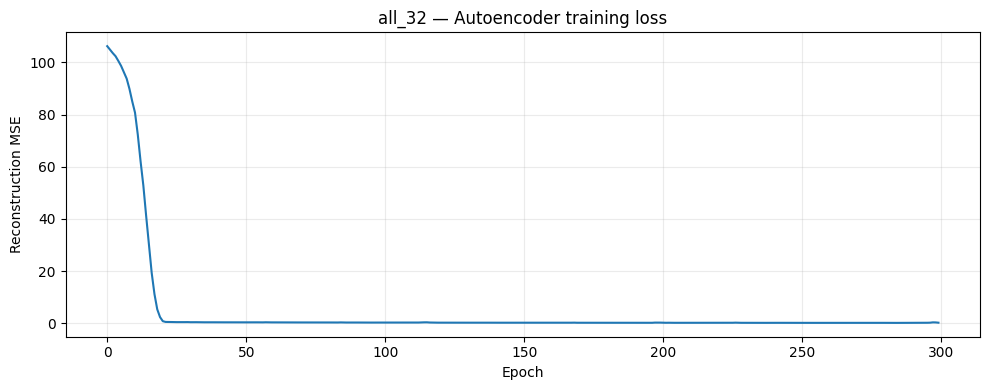

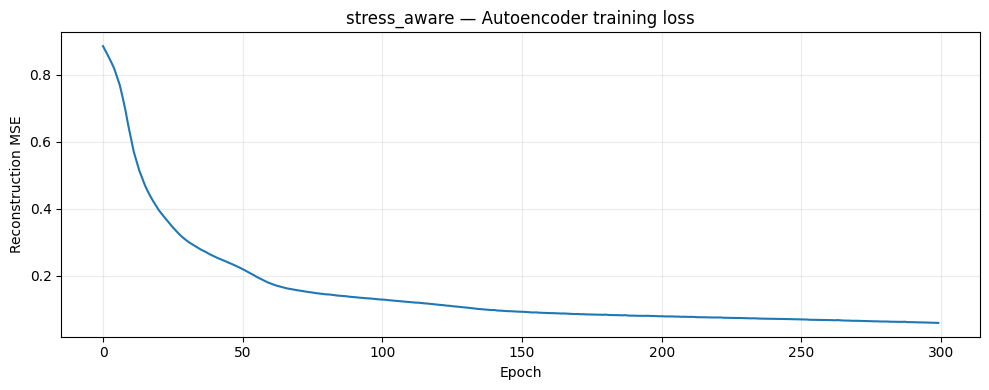

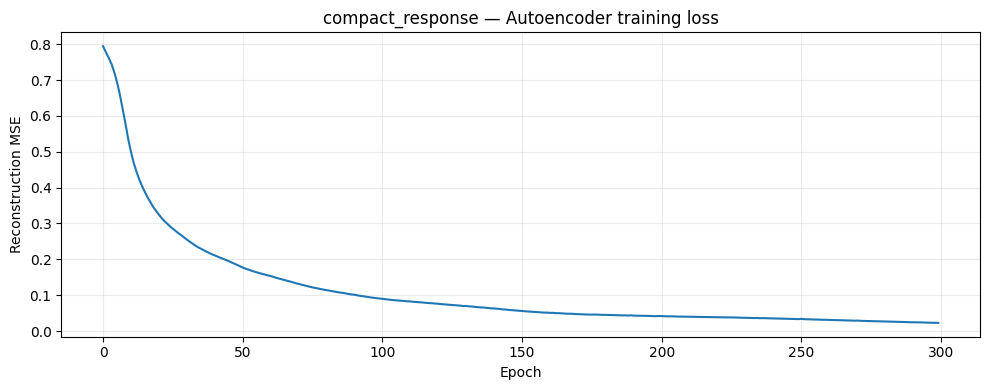

In [9]:
# ============================================================
# TRAINING LOSS
# ============================================================

for experiment_name, losses in (
    autoencoder_losses.items()
):

    plt.figure(
        figsize=(10, 4)
    )

    plt.plot(
        losses
    )

    plt.title(
        f"{experiment_name} — "
        "Autoencoder training loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Reconstruction MSE"
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    plt.show()

In [10]:
# ============================================================
# RECONSTRUCTION SCORE SUMMARY
# ============================================================

ae_score_rows = []

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_ae_score"
    )

    for split_name in [
        "baseline_train",
        "validation",
        "evaluation",
        "check_holdout"
    ]:

        scores = (
            work.loc[
                work["split"] == split_name,
                score_col
            ]
            .dropna()
        )

        if not len(scores):
            continue

        ae_score_rows.append({

            "experiment":
                experiment_name,

            "split":
                split_name,

            "count":
                len(scores),

            "mean":
                scores.mean(),

            "median":
                scores.median(),

            "std":
                scores.std(),

            "q90":
                scores.quantile(0.90),

            "q95":
                scores.quantile(0.95),

            "q99":
                scores.quantile(0.99),

            "max":
                scores.max()
        })


ae_score_summary = pd.DataFrame(
    ae_score_rows
)

display(
    ae_score_summary
)

,experiment,split,count,mean,median,std,q90,q95,q99,max
0,all_32,baseline_train,134,0.192625,0.106996,0.306232,0.265875,0.786052,1.482028,2.192704
1,all_32,validation,134,1.609010,0.788189,2.489404,3.672258,6.690977,11.753652,18.626593
2,all_32,evaluation,415,11.267081,2.664968,25.639506,30.290802,56.993147,131.673025,133.632111
3,all_32,check_holdout,4,5.188235,4.184911,5.722428,10.739410,11.341753,11.823627,11.944096
4,stress_aware,baseline_train,134,0.059250,0.048390,0.040224,0.104602,0.134897,0.207749,0.256781
5,stress_aware,validation,134,0.202015,0.161868,0.151847,0.424955,0.476938,0.717298,0.938878
6,stress_aware,evaluation,415,0.506214,0.246441,1.050448,0.805316,1.678728,4.491089,12.033654
7,stress_aware,check_holdout,4,3.786571,2.522215,4.154606,7.920258,8.680636,9.288939,9.441014
8,compact_response,baseline_train,134,0.022366,0.015681,0.021420,0.047443,0.068028,0.100299,0.130258
9,compact_response,validation,134,0.091884,0.052638,0.095286,0.243332,0.282070,0.411096,0.460941


In [11]:
ae_flag_rows = []

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_ae_score"
    )

    flag_col = (
        f"{experiment_name}_ae_flag"
    )

    threshold = (
        autoencoder_thresholds[
            experiment_name
        ]
    )

    for split_name in [
        "validation",
        "evaluation",
        "check_holdout"
    ]:

        part = work[
            work["split"] == split_name
        ]

        scores = (
            part[score_col]
            .dropna()
        )

        if not len(scores):
            continue

        flags = (
            scores > threshold
        )

        ae_flag_rows.append({

            "experiment":
                experiment_name,

            "split":
                split_name,

            "windows":
                len(scores),

            "flagged":
                int(flags.sum()),

            "flag_fraction":
                flags.mean(),

            "threshold":
                threshold
        })


ae_flag_summary = pd.DataFrame(
    ae_flag_rows
)

display(
    ae_flag_summary
)

,experiment,split,windows,flagged,flag_fraction,threshold
0,all_32,validation,134,7,0.052239,6.690975
1,all_32,evaluation,415,79,0.190361,6.690975
2,all_32,check_holdout,4,2,0.500000,6.690975
3,stress_aware,validation,134,7,0.052239,0.476938
4,stress_aware,evaluation,415,100,0.240964,0.476938
5,stress_aware,check_holdout,4,4,1.000000,0.476938
6,compact_response,validation,134,7,0.052239,0.282070
7,compact_response,evaluation,415,109,0.262651,0.282070
8,compact_response,check_holdout,4,4,1.000000,0.282070


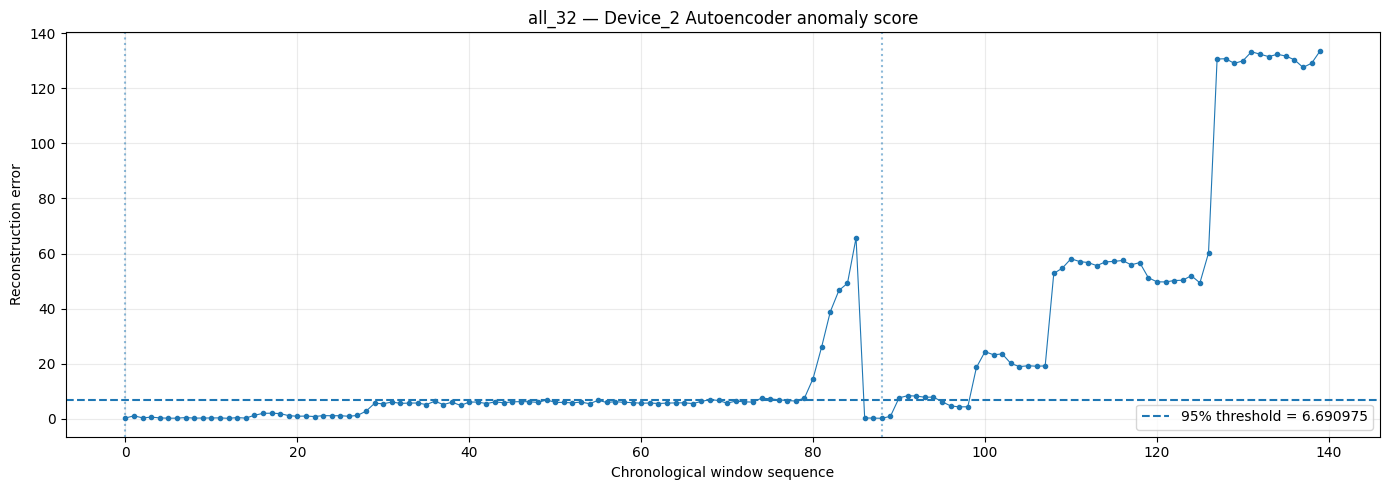

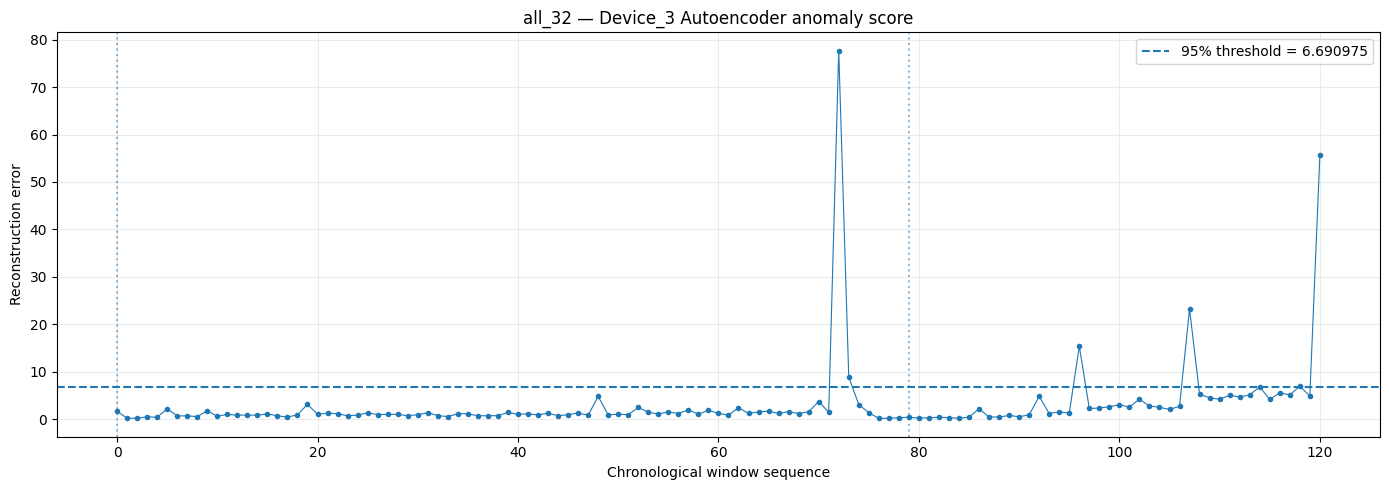

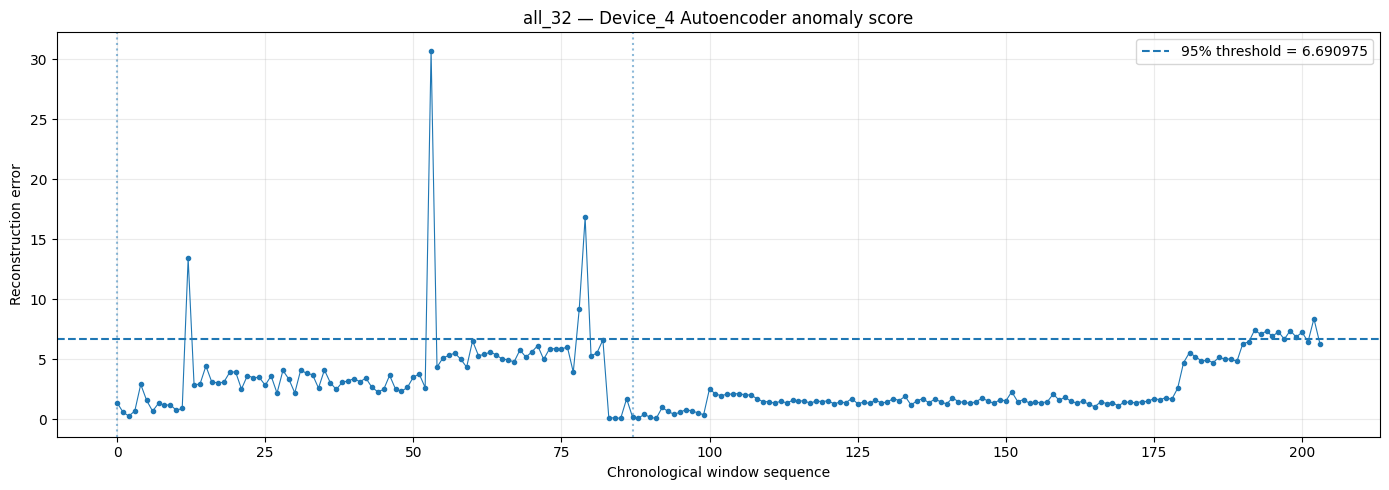

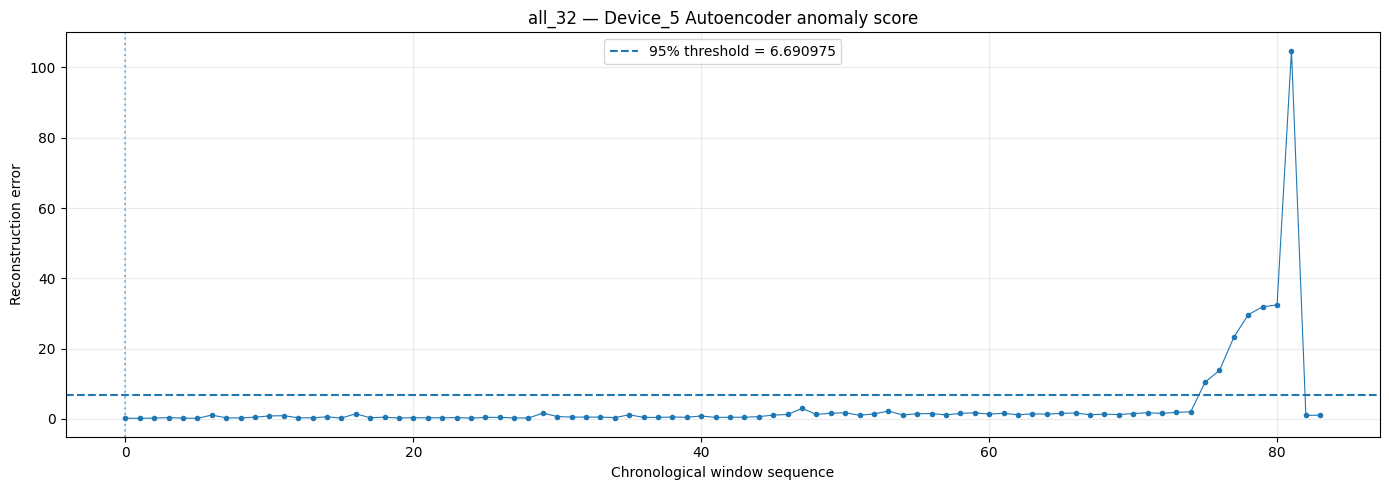

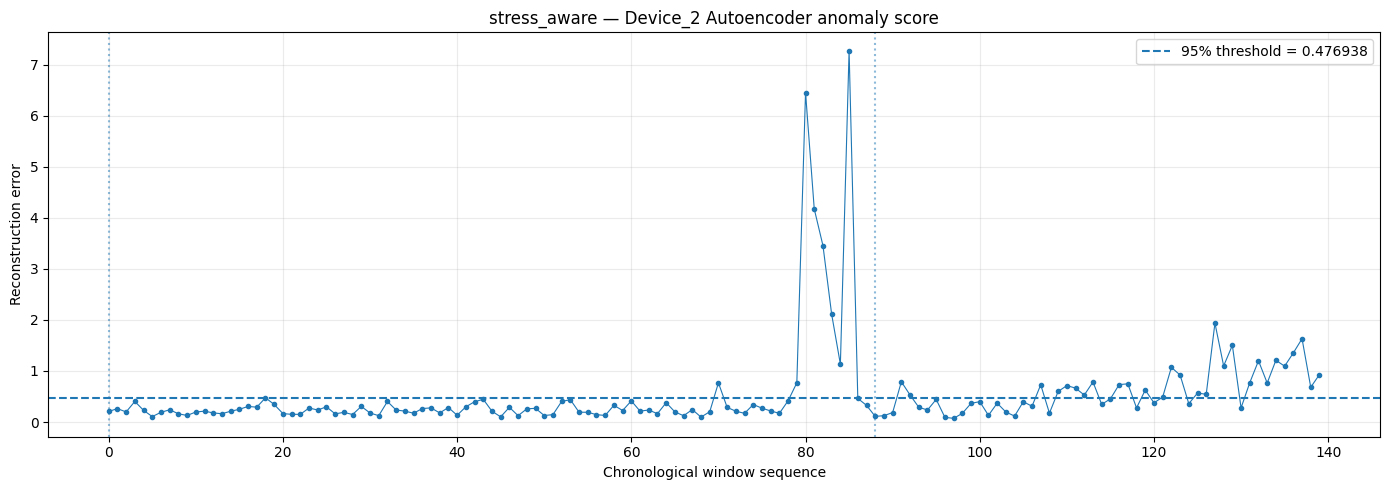

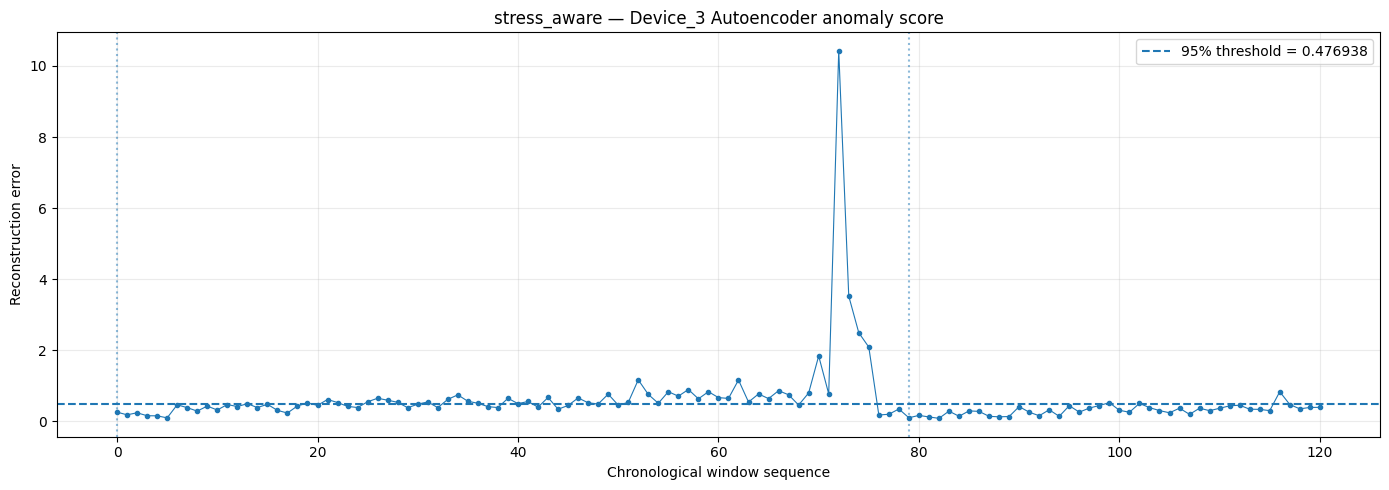

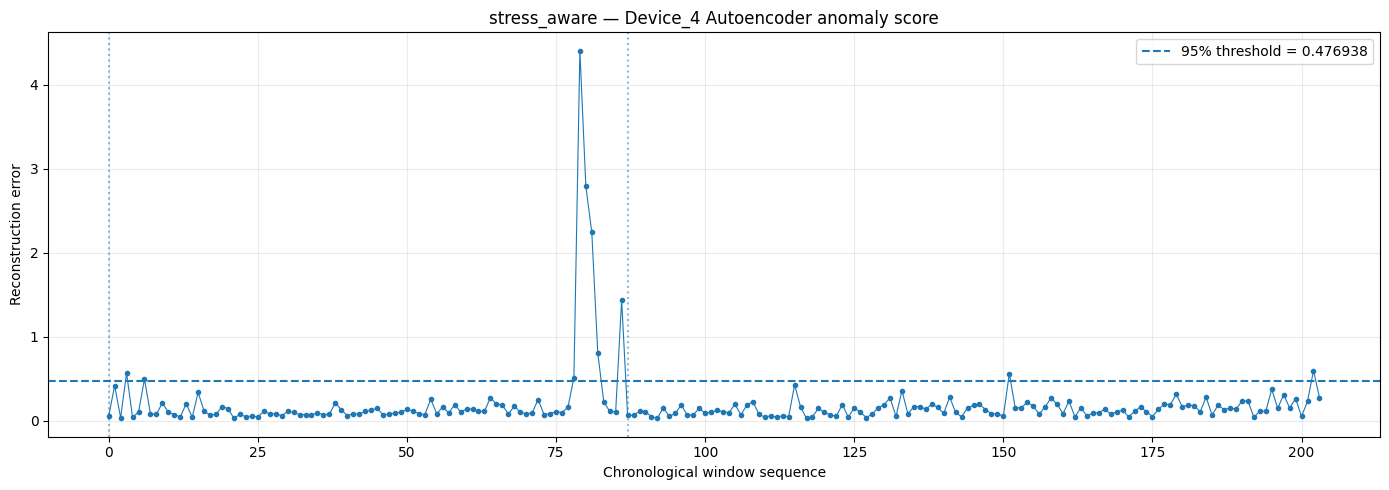

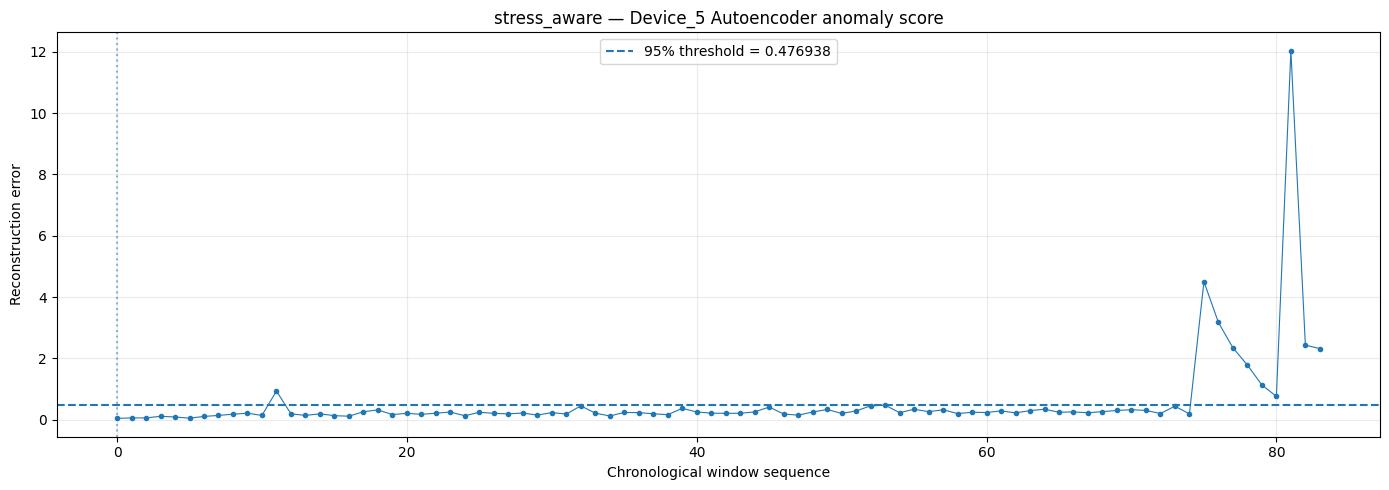

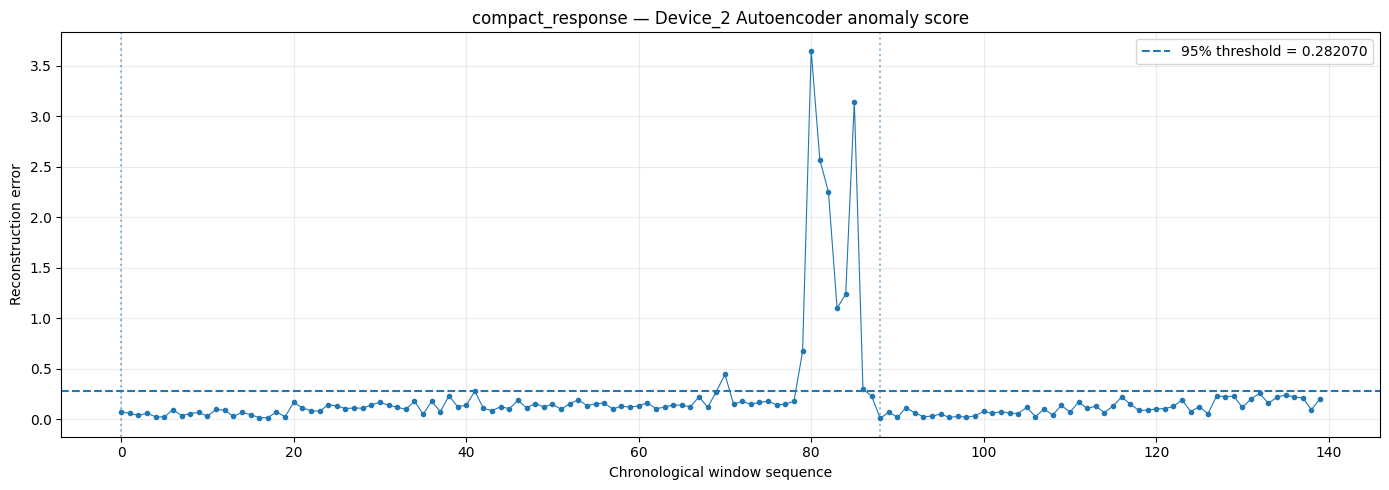

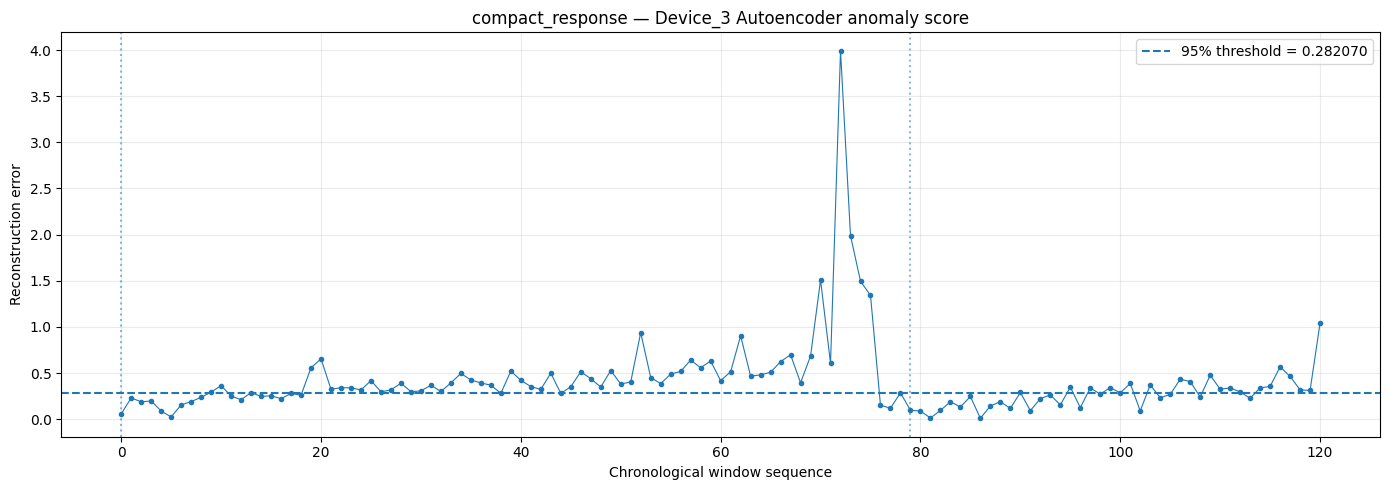

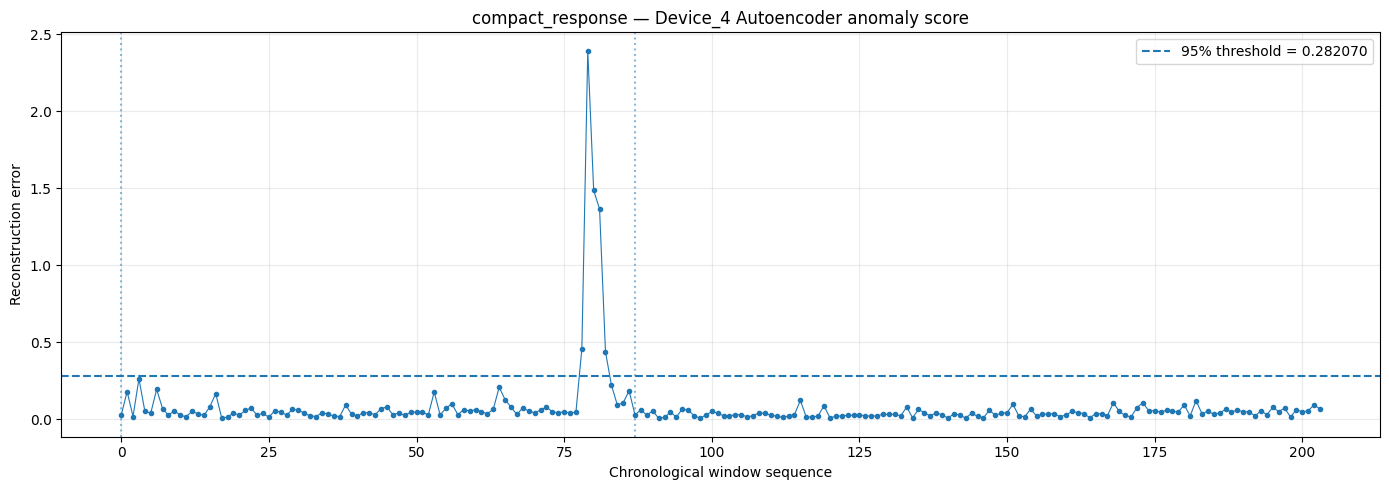

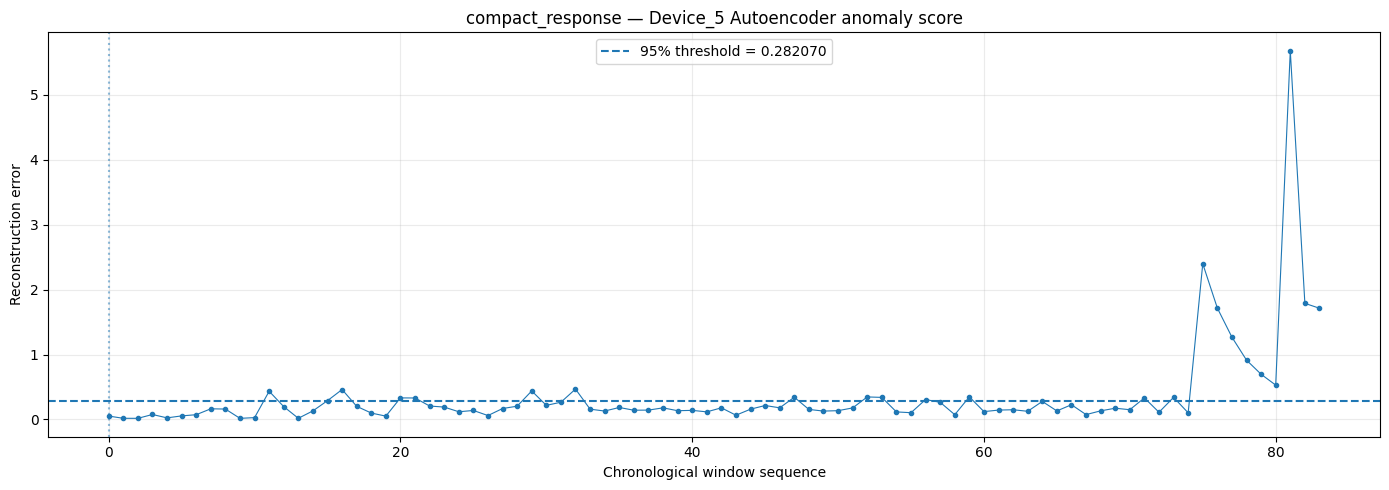

In [12]:
# ============================================================
# AUTOENCODER TIMELINES
# ============================================================

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_ae_score"
    )

    threshold = (
        autoencoder_thresholds[
            experiment_name
        ]
    )

    for device_id, group in work.groupby(
        "device_id"
    ):

        group = group[
            group["split"].isin([
                "validation",
                "evaluation"
            ])
        ].copy()

        if not len(group):
            continue

        group = group.sort_values(
            [
                "file_name",
                "window_index"
            ]
        ).reset_index(
            drop=True
        )

        x = np.arange(
            len(group)
        )

        plt.figure(
            figsize=(14, 5)
        )

        plt.plot(
            x,
            group[score_col],
            marker=".",
            linewidth=0.8
        )

        plt.axhline(
            threshold,
            linestyle="--",
            label=(
                f"95% threshold = "
                f"{threshold:.6f}"
            )
        )

        previous_file = None

        for xpos, file_name in enumerate(
            group["file_name"]
        ):

            if (
                file_name !=
                previous_file
            ):

                plt.axvline(
                    xpos,
                    linestyle=":",
                    alpha=0.5
                )

                previous_file = (
                    file_name
                )

        plt.title(
            f"{experiment_name} — "
            f"{device_id} Autoencoder anomaly score"
        )

        plt.xlabel(
            "Chronological window sequence"
        )

        plt.ylabel(
            "Reconstruction error"
        )

        plt.legend()

        plt.grid(
            alpha=0.25
        )

        plt.tight_layout()

        plt.show()

In [13]:
# ============================================================
# TOP ANOMALOUS WINDOWS
# ============================================================

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_ae_score"
    )

    flag_col = (
        f"{experiment_name}_ae_flag"
    )

    top = (
        work[
            work["split"] == "evaluation"
        ]
        .sort_values(
            score_col,
            ascending=False
        )
        [
            META +
            [
                score_col,
                flag_col
            ]
        ]
        .head(20)
    )

    print(
        "\n" + "=" * 70
    )

    print(
        f"TOP AUTOENCODER ANOMALIES — "
        f"{experiment_name}"
    )

    print(
        "=" * 70
    )

    display(
        top
    )


TOP AUTOENCODER ANOMALIES — all_32


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,all_32_ae_score,all_32_ae_flag
173,173,Device_2,Device2b 1.mat,b,63,100,1461.423000,1483.947000,133.632111,1
165,165,Device_2,Device2b 1.mat,b,55,100,1279.318000,1301.896000,133.247116,1
166,166,Device_2,Device2b 1.mat,b,56,100,1302.152000,1324.606000,132.360016,1
168,168,Device_2,Device2b 1.mat,b,58,100,1347.589000,1370.157000,132.329773,1
169,169,Device_2,Device2b 1.mat,b,59,100,1370.398000,1392.814000,131.702866,1
167,167,Device_2,Device2b 1.mat,b,57,100,1324.842000,1347.348000,131.489716,1
162,162,Device_2,Device2b 1.mat,b,52,100,1211.212000,1233.740000,130.728210,1
161,161,Device_2,Device2b 1.mat,b,51,100,1188.608000,1210.945000,130.605789,1
170,170,Device_2,Device2b 1.mat,b,60,100,1393.057000,1415.608000,130.325027,1
164,164,Device_2,Device2b 1.mat,b,54,100,1256.713000,1279.061000,129.955521,1



TOP AUTOENCODER ANOMALIES — stress_aware


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,stress_aware_ae_score,stress_aware_ae_flag
682,682,Device_5,Device5 1.mat,main,102,100,2317.276999,2339.330999,12.033654,1
266,266,Device_3,Device3 1.mat,main,91,100,2100.673000,2122.623000,10.429774,1
107,107,Device_2,Device2 1.mat,main,107,100,2439.044000,2460.878000,7.278968,1
102,102,Device_2,Device2 1.mat,main,102,100,2327.088000,2349.014000,6.459203,1
676,676,Device_5,Device5 1.mat,main,96,100,2184.038000,2206.366000,4.505102,1
426,426,Device_4,Device4 1.mat,main,100,100,2287.451000,2309.755000,4.405012,1
103,103,Device_2,Device2 1.mat,main,103,100,2349.298000,2371.748000,4.176758,1
267,267,Device_3,Device3 1.mat,main,92,100,2122.887000,2144.965000,3.524297,1
104,104,Device_2,Device2 1.mat,main,104,100,2372.015000,2393.909000,3.458213,1
677,677,Device_5,Device5 1.mat,main,97,100,2206.602000,2228.313000,3.174672,1



TOP AUTOENCODER ANOMALIES — compact_response


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,compact_response_ae_score,compact_response_ae_flag
682,682,Device_5,Device5 1.mat,main,102,100,2317.276999,2339.330999,5.677309,1
266,266,Device_3,Device3 1.mat,main,91,100,2100.673000,2122.623000,3.992798,1
102,102,Device_2,Device2 1.mat,main,102,100,2327.088000,2349.014000,3.647206,1
107,107,Device_2,Device2 1.mat,main,107,100,2439.044000,2460.878000,3.143276,1
103,103,Device_2,Device2 1.mat,main,103,100,2349.298000,2371.748000,2.569357,1
676,676,Device_5,Device5 1.mat,main,96,100,2184.038000,2206.366000,2.397713,1
426,426,Device_4,Device4 1.mat,main,100,100,2287.451000,2309.755000,2.391878,1
104,104,Device_2,Device2 1.mat,main,104,100,2372.015000,2393.909000,2.249718,1
267,267,Device_3,Device3 1.mat,main,92,100,2122.887000,2144.965000,1.989017,1
683,683,Device_5,Device5 1.mat,main,103,100,2339.580999,2361.342000,1.787791,1


In [14]:
# ============================================================
# FEATURE-LEVEL RECONSTRUCTION ERROR
# ============================================================

feature_error_rows = []

for experiment_name, features in FEATURE_SETS.items():

    score_col = (
        f"{experiment_name}_ae_score"
    )

    # preprocessing
    X_raw = (
        work[
            work["split"] == "evaluation"
        ][features]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy()
    )

    imputer = (
        autoencoder_preprocessors[
            experiment_name
        ]["imputer"]
    )

    scaler = (
        autoencoder_preprocessors[
            experiment_name
        ]["scaler"]
    )

    X = scaler.transform(
        imputer.transform(
            X_raw
        )
    )

    errors = feature_reconstruction_errors(
        autoencoder_models[
            experiment_name
        ],
        X
    )

    top_indices = (
        np.argsort(
            work.loc[
                work["split"] == "evaluation",
                score_col
            ].to_numpy()
        )[::-1][:10]
    )

    evaluation_rows = work[
        work["split"] == "evaluation"
    ].reset_index(drop=True)

    for local_idx in top_indices:

        row = (
            evaluation_rows.iloc[
                local_idx
            ]
        )

        for feature_idx, feature in enumerate(
            features
        ):

            feature_error_rows.append({

                "experiment":
                    experiment_name,

                "sample_id":
                    row["sample_id"],

                "device_id":
                    row["device_id"],

                "file_name":
                    row["file_name"],

                "window_index":
                    row["window_index"],

                "anomaly_score":
                    row[score_col],

                "feature":
                    feature,

                "reconstruction_error":
                    errors[
                        local_idx,
                        feature_idx
                    ]
            })


feature_error_df = pd.DataFrame(
    feature_error_rows
)

display(
    feature_error_df
    .sort_values(
        [
            "experiment",
            "sample_id",
            "reconstruction_error"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .head(100)
)

,experiment,sample_id,device_id,file_name,window_index,anomaly_score,feature,reconstruction_error
253,all_32,161,Device_2,Device2b 1.mat,51,130.605789,package_temperature_residual,2598.113770
237,all_32,161,Device_2,Device2b 1.mat,51,130.605789,packageTemperature_std,442.215363
240,all_32,161,Device_2,Device2b 1.mat,51,130.605789,packageTemperature_iqr,373.188019
241,all_32,161,Device_2,Device2b 1.mat,51,130.605789,packageTemperature_slope,103.990219
225,all_32,161,Device_2,Device2b 1.mat,51,130.605789,supplyVoltage_std,91.844254
...,...,...,...,...,...,...,...,...
316,all_32,164,Device_2,Device2b 1.mat,54,129.955521,current_residual_abs,0.246124
61,all_32,165,Device_2,Device2b 1.mat,55,133.247116,package_temperature_residual,2732.437744
45,all_32,165,Device_2,Device2b 1.mat,55,133.247116,packageTemperature_std,415.106506
48,all_32,165,Device_2,Device2b 1.mat,55,133.247116,packageTemperature_iqr,359.629791


In [18]:
# ============================================================
# CELL 15 — COMPLETE MODEL COMPARISON
# ISOLATION FOREST vs AUTOENCODER
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd


# ============================================================
# 1. LOAD ISOLATION FOREST RESULTS
# ============================================================

IF_PATH = (
    PROCESSED /
    "burninwatch_scored_windows_isolation_forest_v1.csv"
)

if not IF_PATH.exists():

    raise FileNotFoundError(
        f"""
Isolation Forest results were not found.

Expected file:
{IF_PATH}

Please make sure Notebook 10 has been executed successfully.
"""
    )


if_results = pd.read_csv(
    IF_PATH
)


print(
    "Isolation Forest results shape:",
    if_results.shape
)

print(
    "Autoencoder results shape:",
    work.shape
)


# ============================================================
# 2. CHECK SAMPLE ID
# ============================================================

if "sample_id" not in if_results.columns:

    raise ValueError(
        "sample_id is missing from Isolation Forest results."
    )


if "sample_id" not in work.columns:

    raise ValueError(
        "sample_id is missing from Autoencoder results."
    )


# ============================================================
# 3. REQUIRED ISOLATION FOREST COLUMNS
# ============================================================

IF_COLUMNS = [

    "sample_id",

    "all_32_anomaly_score",
    "all_32_anomaly_flag",

    "stress_aware_anomaly_score",
    "stress_aware_anomaly_flag",

    "compact_response_anomaly_score",
    "compact_response_anomaly_flag",
]


missing_if_columns = [
    c
    for c in IF_COLUMNS
    if c not in if_results.columns
]


if missing_if_columns:

    raise ValueError(
        "Missing Isolation Forest columns:\n"
        +
        "\n".join(
            f" - {c}"
            for c in missing_if_columns
        )
    )


# ============================================================
# 4. KEEP ONLY REQUIRED IF COLUMNS
# ============================================================

if_small = if_results[
    IF_COLUMNS
].copy()


# ============================================================
# 5. REMOVE OLD IF COLUMNS IF THIS CELL
#    WAS RUN PREVIOUSLY
# ============================================================

old_if_columns = [
    c
    for c in IF_COLUMNS
    if c != "sample_id"
    and c in work.columns
]


if old_if_columns:

    work = work.drop(
        columns=old_if_columns
    )

    print(
        "Removed old IF columns:",
        old_if_columns
    )


# ============================================================
# 6. MERGE ISOLATION FOREST + AUTOENCODER
# ============================================================

comparison_work = work.merge(
    if_small,
    on="sample_id",
    how="inner",
    validate="one_to_one"
)


print(
    "\nMerged comparison shape:",
    comparison_work.shape
)


# ============================================================
# 7. VERIFY ALL 687 WINDOWS MATCH
# ============================================================

if len(comparison_work) != 687:

    raise ValueError(
        f"""
Expected 687 matched windows.

Found:
{len(comparison_work)}
"""
    )


print(
    "✅ All 687 windows matched successfully."
)


# ============================================================
# 8. LOAD ISOLATION FOREST THRESHOLDS
# ============================================================
#
# First choice:
# use the saved artifact created by Notebook 10.
#
# Fallback:
# calculate the 95th percentile from the validation
# scores contained in the Isolation Forest CSV.
#
# This completely removes the dependency on
# `training_summary`.
# ============================================================

IF_ARTIFACT_PATH = (
    MODEL_DIR /
    "burninwatch_isolation_forest_artifacts_v1.json"
)


if_thresholds = {}


# ------------------------------------------------------------
# OPTION A — LOAD SAVED ARTIFACT
# ------------------------------------------------------------

if IF_ARTIFACT_PATH.exists():

    with open(
        IF_ARTIFACT_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        if_artifacts = json.load(f)


    for experiment_name in FEATURE_SETS:

        artifact = if_artifacts.get(
            experiment_name
        )

        if artifact is not None:

            threshold = artifact.get(
                "threshold_95_validation"
            )

            if threshold is not None:

                if_thresholds[
                    experiment_name
                ] = float(threshold)


# ------------------------------------------------------------
# OPTION B — FALLBACK FROM VALIDATION DATA
# ------------------------------------------------------------

for experiment_name in FEATURE_SETS:

    if experiment_name in if_thresholds:

        continue


    score_col = (
        f"{experiment_name}_anomaly_score"
    )


    validation_scores = (
        if_results.loc[
            if_results["split"]
            == "validation",
            score_col
        ]
        .dropna()
    )


    if len(validation_scores) == 0:

        raise ValueError(
            f"""
Could not determine Isolation Forest threshold
for experiment:

{experiment_name}

There are no saved artifact threshold values
and no validation scores available.
"""
        )


    if_thresholds[
        experiment_name
    ] = float(
        validation_scores.quantile(
            0.95
        )
    )


print(
    "\nIsolation Forest thresholds:"
)

for experiment_name, threshold in (
    if_thresholds.items()
):

    print(
        f"{experiment_name:20s}: "
        f"{threshold:.6f}"
    )


# ============================================================
# 9. CHECK AUTOENCODER THRESHOLDS
# ============================================================

for experiment_name in FEATURE_SETS:

    if experiment_name not in (
        autoencoder_thresholds
    ):

        raise ValueError(
            f"""
Autoencoder threshold missing for:
{experiment_name}

Make sure the Autoencoder training cell
has been executed successfully.
"""
        )


# ============================================================
# 10. BUILD COMPARISON
# ============================================================

comparison_rows = []


eval_part = comparison_work[
    comparison_work["split"]
    == "evaluation"
].copy()


print(
    "\nEvaluation windows:",
    len(eval_part)
)


for experiment_name in FEATURE_SETS:


    print(
        "\n" + "=" * 70
    )

    print(
        f"COMPARING: {experiment_name}"
    )

    print(
        "=" * 70
    )


    # --------------------------------------------------------
    # ISOLATION FOREST
    # --------------------------------------------------------

    iso_score_col = (
        f"{experiment_name}_anomaly_score"
    )

    iso_flag_col = (
        f"{experiment_name}_anomaly_flag"
    )

    iso_threshold = (
        if_thresholds[
            experiment_name
        ]
    )


    iso_scores = (
        eval_part[
            iso_score_col
        ]
        .dropna()
    )


    iso_flags = (
        iso_scores
        > iso_threshold
    )


    # --------------------------------------------------------
    # AUTOENCODER
    # --------------------------------------------------------

    ae_score_col = (
        f"{experiment_name}_ae_score"
    )

    ae_flag_col = (
        f"{experiment_name}_ae_flag"
    )

    ae_threshold = float(
        autoencoder_thresholds[
            experiment_name
        ]
    )


    ae_scores = (
        eval_part[
            ae_score_col
        ]
        .dropna()
    )


    ae_flags = (
        ae_scores
        > ae_threshold
    )


    # --------------------------------------------------------
    # BASIC STATISTICS
    # --------------------------------------------------------

    IF_flagged = int(
        iso_flags.sum()
    )

    AE_flagged = int(
        ae_flags.sum()
    )


    IF_fraction = float(
        iso_flags.mean()
    )


    AE_fraction = float(
        ae_flags.mean()
    )


    # --------------------------------------------------------
    # ALIGN BOTH FLAGS USING SAMPLE_ID
    # --------------------------------------------------------

    paired = eval_part[
        [
            "sample_id",
            iso_score_col,
            ae_score_col,
            iso_flag_col,
            ae_flag_col,
        ]
    ].copy()


    paired = paired.dropna(
        subset=[
            iso_score_col,
            ae_score_col,
        ]
    )


    iso_flag_series = (
        paired[
            iso_flag_col
        ]
        .fillna(0)
        .astype(int)
    )


    ae_flag_series = (
        paired[
            ae_flag_col
        ]
        .fillna(0)
        .astype(int)
    )


    # --------------------------------------------------------
    # MODEL AGREEMENT
    # --------------------------------------------------------

    both_flagged = int(
        (
            (iso_flag_series == 1)
            &
            (ae_flag_series == 1)
        ).sum()
    )


    IF_only = int(
        (
            (iso_flag_series == 1)
            &
            (ae_flag_series == 0)
        ).sum()
    )


    AE_only = int(
        (
            (iso_flag_series == 0)
            &
            (ae_flag_series == 1)
        ).sum()
    )


    neither_flagged = int(
        (
            (iso_flag_series == 0)
            &
            (ae_flag_series == 0)
        ).sum()
    )


    # --------------------------------------------------------
    # SCORE CORRELATION
    # --------------------------------------------------------

    if len(paired) >= 2:

        score_correlation = float(
            paired[
                iso_score_col
            ].corr(
                paired[
                    ae_score_col
                ]
            )
        )

    else:

        score_correlation = np.nan


    # --------------------------------------------------------
    # SAVE RESULT
    # --------------------------------------------------------

    comparison_rows.append({

        "experiment":
            experiment_name,

        "feature_count":
            len(
                FEATURE_SETS[
                    experiment_name
                ]
            ),

        "evaluation_windows":
            len(eval_part),


        # ----------------------------------------------------
        # Isolation Forest
        # ----------------------------------------------------

        "IF_threshold":
            iso_threshold,

        "IF_flagged":
            IF_flagged,

        "IF_flag_fraction":
            IF_fraction,

        "IF_mean_score":
            float(
                iso_scores.mean()
            ),

        "IF_median_score":
            float(
                iso_scores.median()
            ),

        "IF_q95":
            float(
                iso_scores.quantile(
                    0.95
                )
            ),

        "IF_max_score":
            float(
                iso_scores.max()
            ),


        # ----------------------------------------------------
        # Autoencoder
        # ----------------------------------------------------

        "AE_threshold":
            ae_threshold,

        "AE_flagged":
            AE_flagged,

        "AE_flag_fraction":
            AE_fraction,

        "AE_mean_score":
            float(
                ae_scores.mean()
            ),

        "AE_median_score":
            float(
                ae_scores.median()
            ),

        "AE_q95":
            float(
                ae_scores.quantile(
                    0.95
                )
            ),

        "AE_max_score":
            float(
                ae_scores.max()
            ),


        # ----------------------------------------------------
        # AGREEMENT
        # ----------------------------------------------------

        "both_models_flagged":
            both_flagged,

        "IF_only_flagged":
            IF_only,

        "AE_only_flagged":
            AE_only,

        "neither_flagged":
            neither_flagged,

        "score_correlation":
            score_correlation,
    })


# ============================================================
# 11. FINAL DATAFRAME
# ============================================================

model_comparison = pd.DataFrame(
    comparison_rows
)


print(
    "\n" + "=" * 80
)

print(
    "BURNINWATCH — ISOLATION FOREST vs AUTOENCODER"
)

print(
    "=" * 80
)

display(
    model_comparison
)


# ============================================================
# 12. SAVE RESULTS
# ============================================================

comparison_path = (
    PROCESSED /
    "burninwatch_isolation_vs_autoencoder_v1.csv"
)

combined_path = (
    PROCESSED /
    "burninwatch_combined_model_scores_v1.csv"
)


model_comparison.to_csv(
    comparison_path,
    index=False
)


comparison_work.to_csv(
    combined_path,
    index=False
)


print(
    "\n✅ Comparison saved:"
)

print(
    comparison_path
)

print(
    "\n✅ Combined model scores saved:"
)

print(
    combined_path
)


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

assert len(model_comparison) == 3

assert set(
    model_comparison["experiment"]
) == set(
    FEATURE_SETS.keys()
)

assert len(comparison_work) == 687

print(
    "\n✅ CELL 15 COMPLETED SUCCESSFULLY."
)

Isolation Forest results shape: (687, 47)
Autoencoder results shape: (687, 47)

Merged comparison shape: (687, 53)
✅ All 687 windows matched successfully.

Isolation Forest thresholds:
all_32              : 0.102613
stress_aware        : 0.043463
compact_response    : 0.052215

Evaluation windows: 415

COMPARING: all_32

COMPARING: stress_aware

COMPARING: compact_response

BURNINWATCH — ISOLATION FOREST vs AUTOENCODER


,experiment,feature_count,evaluation_windows,IF_threshold,IF_flagged,IF_flag_fraction,IF_mean_score,IF_median_score,IF_q95,IF_max_score,AE_threshold,AE_flagged,AE_flag_fraction,AE_mean_score,AE_median_score,AE_q95,AE_max_score,both_models_flagged,IF_only_flagged,AE_only_flagged,neither_flagged,score_correlation
0,all_32,32,415,0.102613,41,0.098795,0.078790,0.080167,0.114271,0.188978,6.690975,79,0.190361,11.267081,2.664968,56.993147,133.632111,21,20,58,316,0.255447
1,stress_aware,17,415,0.043463,47,0.113253,-0.003464,-0.005059,0.079931,0.196099,0.476938,100,0.240964,0.506214,0.246441,1.678728,12.033654,36,11,64,304,0.654975
2,compact_response,14,415,0.052215,58,0.139759,0.006895,0.009198,0.098084,0.210447,0.282070,109,0.262651,0.275691,0.129283,0.969026,5.677309,41,17,68,289,0.676015



✅ Comparison saved:
processed\burninwatch_isolation_vs_autoencoder_v1.csv

✅ Combined model scores saved:
processed\burninwatch_combined_model_scores_v1.csv

✅ CELL 15 COMPLETED SUCCESSFULLY.


In [19]:
# ============================================================
# SAVE AUTOENCODER ARTIFACTS
# ============================================================

scored_path = (
    PROCESSED /
    "burninwatch_scored_windows_autoencoder_v1.csv"
)

work.to_csv(
    scored_path,
    index=False
)

ae_score_summary.to_csv(
    PROCESSED /
    "burninwatch_autoencoder_score_summary_v1.csv",
    index=False
)

ae_flag_summary.to_csv(
    PROCESSED /
    "burninwatch_autoencoder_flag_summary_v1.csv",
    index=False
)

model_comparison.to_csv(
    PROCESSED /
    "burninwatch_isolation_vs_autoencoder_v1.csv",
    index=False
)

feature_error_df.to_csv(
    PROCESSED /
    "burninwatch_autoencoder_feature_errors_v1.csv",
    index=False
)

# Save model parameters + preprocessing.
artifact_metadata = {}

for experiment_name in FEATURE_SETS:

    model_path = (
        MODEL_DIR /
        f"burninwatch_{experiment_name}_autoencoder.pt"
    )

    torch.save(
        autoencoder_models[
            experiment_name
        ].state_dict(),
        model_path
    )

    artifact_metadata[
        experiment_name
    ] = {

        "features":
            FEATURE_SETS[
                experiment_name
            ],

        "input_dim":
            len(
                FEATURE_SETS[
                    experiment_name
                ]
            ),

        "bottleneck_dim":
            8,

        "threshold_95_validation":
            float(
                autoencoder_thresholds[
                    experiment_name
                ]
            ),

        "model_path":
            str(model_path)
    }


with open(
    MODEL_DIR /
    "burninwatch_autoencoder_artifacts_v1.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        artifact_metadata,
        f,
        indent=2
    )


print("Saved all autoencoder artifacts.")

Saved all autoencoder artifacts.


In [20]:
assert len(work) == 687

for experiment_name in FEATURE_SETS:

    assert (
        f"{experiment_name}_ae_score"
        in work.columns
    )

    assert (
        f"{experiment_name}_ae_flag"
        in work.columns
    )

print(
    "\n" + "=" * 70
)

print(
    "✅ BURNINWATCH AUTOENCODER STAGE COMPLETE"
)

print(
    "=" * 70
)

display(
    model_comparison
)


✅ BURNINWATCH AUTOENCODER STAGE COMPLETE


,experiment,feature_count,evaluation_windows,IF_threshold,IF_flagged,IF_flag_fraction,IF_mean_score,IF_median_score,IF_q95,IF_max_score,AE_threshold,AE_flagged,AE_flag_fraction,AE_mean_score,AE_median_score,AE_q95,AE_max_score,both_models_flagged,IF_only_flagged,AE_only_flagged,neither_flagged,score_correlation
0,all_32,32,415,0.102613,41,0.098795,0.078790,0.080167,0.114271,0.188978,6.690975,79,0.190361,11.267081,2.664968,56.993147,133.632111,21,20,58,316,0.255447
1,stress_aware,17,415,0.043463,47,0.113253,-0.003464,-0.005059,0.079931,0.196099,0.476938,100,0.240964,0.506214,0.246441,1.678728,12.033654,36,11,64,304,0.654975
2,compact_response,14,415,0.052215,58,0.139759,0.006895,0.009198,0.098084,0.210447,0.282070,109,0.262651,0.275691,0.129283,0.969026,5.677309,41,17,68,289,0.676015
